# 04 · Engenharia de features

Aqui as hipóteses do notebook 03 viram variáveis. Três princípios guiam todas as decisões:

1. **Disponibilidade no momento da decisão:** só entra o que existe quando o pagamento chega (payload
   da transação + tabelas de referência aprendidas no treino). Nada de informação do futuro.
2. **Paridade treino/produção:** as features ficam em um único módulo,
   [`src/fraude/features.py`](../src/fraude/features.py), usado no treino, na avaliação e na
   inferência online. Isso elimina o risco de reimplementar a lógica de forma diferente na API.
3. **Sem vazamento do alvo:** features calculadas a partir do rótulo (taxa de fraude da categoria e
   score do título) são geradas *out-of-fold* no treino.

In [1]:
# Configuração comum a todos os notebooks do projeto
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fraude import config as cfg, dados, metricas, graficos as gr

gr.aplicar_estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 40)

import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score
from fraude.features import ConstrutorFeatures
from fraude import validacao

In [2]:
base = dados.carregar_base()
tr = base[base["particao"] == "treino"].reset_index(drop=True)
va = base[base["particao"] == "validacao"].reset_index(drop=True)
dev = base[base["particao"] != "teste"].reset_index(drop=True)   # treino + validação
print(f"treino {len(tr):,} | validação {len(va):,} | dev (treino+validação) {len(dev):,}")

treino 76,961 | validação 31,505 | dev (treino+validação) 108,466


## 1. Catálogo de features

In [3]:
cf = ConstrutorFeatures()
X_tr = cf.fit_transform(tr, tr["fraude"])
X_va = cf.transform(va)

catalogo = pd.DataFrame([
    ("a, b, c, d, e, f, h, l, m, n", "payload", "numéricas brutas (nulos preservados)", "sinais de histórico/relacionamento (nb 03)"),
    ("monto", "payload", "valor do pagamento", "risco cresce com o valor"),
    ("o_Y, o_N", "payload", "dummies de o (nulo = ambas 0)", "o tem 3 estados com risco muito distinto"),
    ("p_Y", "payload", "binária", "p = N tem 2,6x o risco"),
    ("pais_*", "payload", "dummies dos países com 500+ transações no treino + pais_nulo", "BR/AR/UY/US têm riscos distintos"),
    ("hora, madrugada, dia_semana", "payload (fecha)", "componentes de data-hora", "fraude ~2,2x maior entre 0h e 5h"),
    ("cat_taxa_fraude", "tabela de referência", "taxa de fraude da categoria j, suavizada (out-of-fold)", "categorias com risco de ~1% a ~27%"),
    ("cat_volume_log", "tabela de referência", "log do nº de transações da categoria no treino", "categorias raras x populares"),
    ("titulo_score", "modelo de texto", "TF-IDF + logística sobre o título i (out-of-fold)", "celulares, gift cards etc."),
], columns=["feature", "origem", "construção", "racional"])
print(f"{X_tr.shape[1]} features:", list(X_tr.columns))
catalogo

25 features: ['a', 'b', 'c', 'd', 'e', 'f', 'h', 'l', 'm', 'n', 'monto', 'o_Y', 'o_N', 'p_Y', 'pais_AR', 'pais_BR', 'pais_US', 'pais_UY', 'pais_nulo', 'hora', 'madrugada', 'dia_semana', 'cat_taxa_fraude', 'cat_volume_log', 'titulo_score']


,feature,origem,construção,racional
0,"a, b, c, d, e, f, h, l, m, n",payload,numéricas brutas (nulos preservados),sinais de histórico/relacionamento (nb 03)
1,monto,payload,valor do pagamento,risco cresce com o valor
2,"o_Y, o_N",payload,dummies de o (nulo = ambas 0),o tem 3 estados com risco muito distinto
3,p_Y,payload,binária,"p = N tem 2,6x o risco"
4,pais_*,payload,dummies dos países com 500+ transações no trei...,BR/AR/UY/US têm riscos distintos
5,"hora, madrugada, dia_semana",payload (fecha),componentes de data-hora,"fraude ~2,2x maior entre 0h e 5h"
6,cat_taxa_fraude,tabela de referência,"taxa de fraude da categoria j, suavizada (out-...",categorias com risco de ~1% a ~27%
7,cat_volume_log,tabela de referência,log do nº de transações da categoria no treino,categorias raras x populares
8,titulo_score,modelo de texto,TF-IDF + logística sobre o título i (out-of-fold),"celulares, gift cards etc."


**Fora do modelo, de propósito:** `k` (ruído, nb 03), o título e a categoria brutos (entram via
`titulo_score` e `cat_*`) e `score`. O novo modelo deve ser **independente** do atual para poder
substituí-lo. A combinação dos dois é avaliada à parte no notebook 07.

## 2. Por que *out-of-fold*? Uma demonstração de vazamento

Se calcularmos a taxa de fraude da categoria usando **as próprias linhas** do treino, a variável
"enxerga" o rótulo de cada transação. Ela parece excelente no treino e decepciona no futuro.
Comparamos três versões da mesma variável:

In [4]:
def auc(y, x):
    return roc_auc_score(y, x)

# Versões "ingênuas": ajustadas e aplicadas no MESMO conjunto de treino
cf_ingenuo = ConstrutorFeatures().fit(tr, tr["fraude"])
X_tr_ingenuo = cf_ingenuo.transform(tr)

vazamento = pd.DataFrame({
    "treino: in-sample (vazado)": [auc(tr["fraude"], X_tr_ingenuo[c]) for c in ["cat_taxa_fraude", "titulo_score"]],
    "treino: out-of-fold": [auc(tr["fraude"], X_tr[c]) for c in ["cat_taxa_fraude", "titulo_score"]],
    "validação (futuro)": [auc(va["fraude"], X_va[c]) for c in ["cat_taxa_fraude", "titulo_score"]],
}, index=["cat_taxa_fraude", "titulo_score"])
vazamento

,treino: in-sample (vazado),treino: out-of-fold,validação (futuro)
cat_taxa_fraude,0.7662,0.6360,0.6313
titulo_score,0.8602,0.6472,0.6365


A versão in-sample do `titulo_score` tem AUC muito alto no treino, que **não se sustenta** no futuro.
Um modelo treinado com ela confiaria demais nessa variável. A versão *out-of-fold* tem, no treino, um AUC
**coerente com o que acontece na validação**, que é exatamente o comportamento desejado.

## 3. Poder individual das novas features (ajustadas no treino, medidas na validação)

In [5]:
novas = ["cat_taxa_fraude", "titulo_score", "cat_volume_log", "hora", "madrugada", "o_N", "p_Y"]
poder = pd.Series({c: max(auc(va["fraude"], X_va[c]), 1 - auc(va["fraude"], X_va[c])) for c in novas},
                  name="ROC AUC univariado (validação)").sort_values(ascending=False)
poder.to_frame().T

,o_N,titulo_score,cat_taxa_fraude,p_Y,cat_volume_log,madrugada,hora
ROC AUC univariado (validação),0.7088,0.6365,0.6313,0.6243,0.5538,0.5299,0.5130


`o_N`, `cat_taxa_fraude` e `titulo_score` têm poder individual comparável às melhores variáveis brutas.
O que importa, porém, é o **ganho incremental** sobre o restante, medido a seguir.

## 4. Teste de ablação com validação cruzada temporal

Medimos o ganho de cada **grupo** de features com um LightGBM de hiperparâmetros fixos (o algoritmo
ainda não foi escolhido, então é só um instrumento de medida), nos 3 folds temporais do notebook 01.

Também testamos duas ideias que **não entraram** na proposta:
- **`k`**, para confirmar empiricamente que é ruído;
- **features de velocidade**: nº de transações com o mesmo título/categoria nas últimas 1h/24h/7d,
  calculadas só com o passado. São clássicas em fraude, mas a base é uma *amostra*, então esses
  contadores teriam outra escala em produção. Só valeria a pena se o ganho fosse claro.

In [6]:
def contagem_passada(df, chave, janela):
    """Nº de transações com a mesma `chave` no intervalo [t - janela, t). Usa só o passado."""
    s = df[["fecha", chave]].copy()
    s["um"], s["pos"] = 1.0, np.arange(len(s))
    out = np.zeros(len(s))
    for _, g in s.groupby(chave, sort=False):
        if len(g) > 1:
            out[g["pos"].to_numpy()] = (g.set_index("fecha")["um"].rolling(janela, closed="left")
                                         .sum().fillna(0).to_numpy())
    return out

velocidade = pd.DataFrame({
    "vel_titulo_24h": contagem_passada(dev, "i", "24h"),
    "vel_titulo_7d": contagem_passada(dev, "i", "7D"),
    "vel_categoria_1h": contagem_passada(dev, "j", "1h"),
    "vel_categoria_24h": contagem_passada(dev, "j", "24h"),
})
velocidade.describe().T[["mean", "50%", "max"]]

,mean,50%,max
vel_titulo_24h,0.0520,0.0000,26.0000
vel_titulo_7d,0.1731,0.0000,42.0000
vel_categoria_1h,0.4077,0.0000,15.0000
vel_categoria_24h,6.9915,2.0000,127.0000


In [7]:
%%time
folds = validacao.construir_folds(dev)   # features ajustadas só no passado de cada fold
for f in folds:                          # anexa as colunas experimentais (k e velocidade)
    for X, idx in [(f.X_tr, np.arange(len(f.y_tr))), (f.X_va, f.idx_va)]:
        X["k"] = dev.loc[idx, "k"].to_numpy()
        for c in velocidade:
            X[c] = velocidade.loc[idx, c].to_numpy()

CPU times: total: 17 s
Wall time: 39.6 s


In [8]:
brutas = ["a", "b", "c", "d", "e", "f", "h", "l", "m", "n", "monto", "o_Y", "o_N", "p_Y"] + \
         [c for c in folds[0].X_tr if c.startswith("pais_")]
tempo = ["hora", "madrugada", "dia_semana"]
categoria = ["cat_taxa_fraude", "cat_volume_log"]
texto = ["titulo_score"]

configs = {
    "A · brutas": brutas,
    "B · A + tempo": brutas + tempo,
    "C · B + categoria": brutas + tempo + categoria,
    "D · C + texto (proposta)": brutas + tempo + categoria + texto,
    "E · D + k": brutas + tempo + categoria + texto + ["k"],
    "F · D + velocidade": brutas + tempo + categoria + texto + list(velocidade.columns),
}
lgbm_fixo = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=100,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                               random_state=cfg.SEED, verbose=-1)
res = pd.concat([validacao.avaliar_cv(lgbm_fixo, folds, cols, nome)[0] for nome, cols in configs.items()])
ablacao = res.groupby("modelo", sort=False)[["PR AUC", "ROC AUC", "Recall @ FPR 5%"]].mean()
ablacao["Δ PR AUC vs A"] = ablacao["PR AUC"] - ablacao.loc["A · brutas", "PR AUC"]
ablacao

,PR AUC,ROC AUC,Recall @ FPR 5%,Δ PR AUC vs A
modelo,,,,
A · brutas,0.3956,0.8465,0.4574,0.0000
B · A + tempo,0.4079,0.8503,0.4649,0.0123
C · B + categoria,0.4146,0.8521,0.4808,0.0189
D · C + texto (proposta),0.4177,0.8534,0.4807,0.0221
E · D + k,0.4165,0.8530,0.4835,0.0209
F · D + velocidade,0.4208,0.8529,0.4831,0.0251


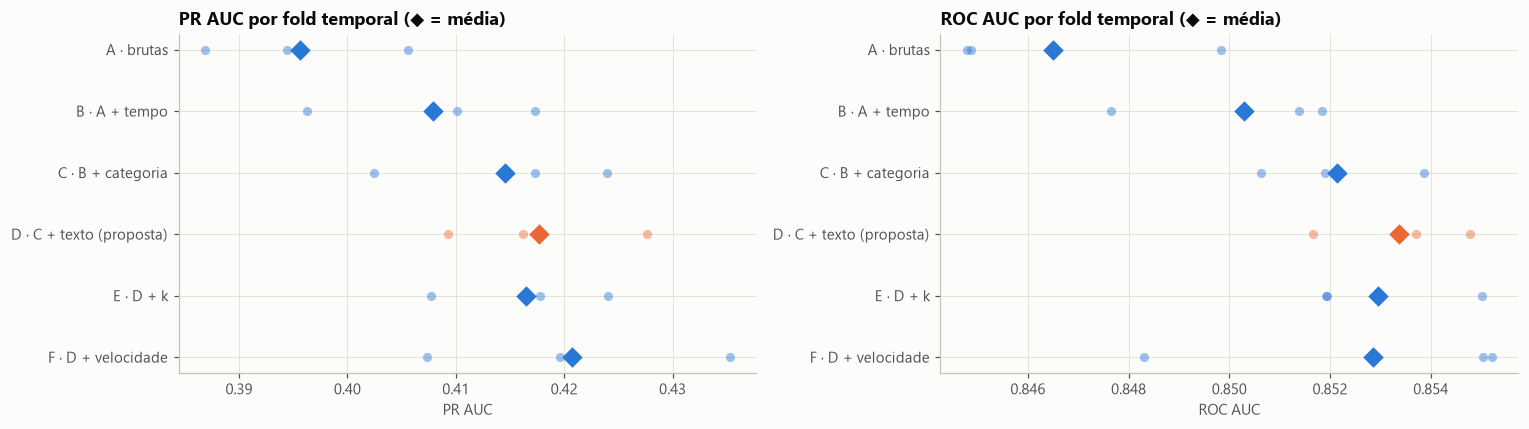

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
nomes = list(configs)
for ax, met in zip(axes, ["PR AUC", "ROC AUC"]):
    for i, nome in enumerate(nomes):
        v = res.loc[res["modelo"] == nome, met]
        cor = gr.LARANJA if "proposta" in nome else gr.AZUL
        ax.scatter(v, [i] * len(v), color=cor, s=36, alpha=0.45, zorder=3)
        ax.scatter(v.mean(), i, color=cor, s=90, marker="D", zorder=4)
    ax.set_yticks(range(len(nomes)), nomes)
    ax.invert_yaxis()
    ax.set(title=f"{met} por fold temporal (◆ = média)", xlabel=met)
plt.tight_layout()

Como os folds têm dificuldades diferentes, a comparação mais justa é **pareada**: o ganho de cada
grupo **dentro do mesmo fold**.

In [10]:
def deltas_pareados(met):
    t = res.pivot(index="modelo", columns="fold", values=met).loc[nomes]
    d = pd.DataFrame({
        "B − A (tempo)": t.loc[nomes[1]] - t.loc[nomes[0]],
        "C − B (categoria)": t.loc[nomes[2]] - t.loc[nomes[1]],
        "D − C (texto)": t.loc[nomes[3]] - t.loc[nomes[2]],
        "E − D (k)": t.loc[nomes[4]] - t.loc[nomes[3]],
        "F − D (velocidade)": t.loc[nomes[5]] - t.loc[nomes[3]],
    }).T
    d.columns = [f"fold {c}" for c in d.columns]
    d["média"] = d.mean(axis=1)
    d["folds com ganho"] = (d.iloc[:, :3] > 0).sum(axis=1).astype(str) + "/3"
    return d

display(deltas_pareados("PR AUC").style.format(precision=4).set_caption("Δ PR AUC por fold"))
display(deltas_pareados("ROC AUC").style.format(precision=4).set_caption("Δ ROC AUC por fold"))

,fold 1,fold 2,fold 3,média,folds com ganho
B − A (tempo),0.0094,0.0117,0.0157,0.0123,3/3
C − B (categoria),0.0062,0.0066,0.0072,0.0067,3/3
D − C (texto),0.0068,0.0037,-0.0011,0.0031,2/3
E − D (k),-0.0015,-0.0036,0.0016,-0.0012,1/3
F − D (velocidade),-0.0019,0.0076,0.0034,0.0031,2/3


,fold 1,fold 2,fold 3,média,folds com ganho
B − A (tempo),0.0066,0.0028,0.0020,0.0038,3/3
C − B (categoria),-0.0007,0.0042,0.0020,0.0018,2/3
D − C (texto),0.0010,0.0018,0.0009,0.0012,3/3
E − D (k),0.0003,-0.0018,0.0002,-0.0004,2/3
F − D (velocidade),-0.0033,0.0013,0.0004,-0.0005,2/3


**Leitura da ablação (comparação pareada):**
- **Tempo (B):** maior ganho incremental (+0,012 de PR AUC), positivo nos 3 folds e nas duas métricas.
- **Categoria (C):** +0,007 de PR AUC, positivo nos 3 folds.
- **Texto (D):** ganho menor (+0,003 PR AUC / +0,001 ROC AUC), positivo em 2 de 3 folds no PR AUC e
  em 3 de 3 no ROC AUC. **Mantido**, e seu custo/benefício em latência será reavaliado no notebook 09.
- **`k` (E):** piora as duas métricas na média, o que **confirma a exclusão**.
- **Velocidade (F):** ganho médio em PR AUC parecido com o do texto, mas **instável** (negativo no fold 1)
  e **sem ganho em ROC AUC**. O fator decisivo é o risco de produção: como a base é uma *amostra*, os
  contadores teriam outra escala com o tráfego completo (*training-serving skew*). **Descartada** neste
  ciclo. Com o histórico completo de transações, é a primeira frente a revisitar, junto de variáveis por
  **usuário/dispositivo/cartão**, que não existem nesta base.

> Os ganhos de C e D são pequenos perto da variação entre folds. A decisão de mantê-los se apoia
> também na **direção consistente** e na **plausibilidade de negócio** (nb 03), e não só na média.

## 5. Conjunto final de features

**Configuração D:** 25 features = 11 numéricas brutas + `o`/`p` + países + tempo + categoria + texto,
todas produzidas por `ConstrutorFeatures` (padrão: `usar_categoria=True`, `usar_texto=True`).

➡️ **Próximo passo (05):** com as features definidas, comparar famílias de algoritmos.